# Module 09 — Exercises — Solutions

These exercises follow the order of the concept guide: joint tables, covariance and correlation, covariance
matrices, the multivariate Gaussian and its conditioning formulas, Simpson's paradox, the Mahalanobis distance,
Gaussian processes, and finally a Kalman-filter mini-project. Several checks compare your answer against a
*hidden* value, so compute carefully rather than guessing. Use only NumPy (and SciPy where a prompt says so).

This notebook contains reference solutions and explanations for every exercise. Try the exercises yourself first — the learning happens in the struggle.

### Setup and self-check helpers
Run the next two cells first.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
rng = np.random.default_rng(0)
plt.rcParams["figure.figsize"] = (7, 4)

In [2]:
import hashlib as _hashlib
import numpy as _np

_results = {}

def _canon(value, decimals=3):
    """Canonical string form of an answer, so hashes are stable."""
    if isinstance(value, (bool, _np.bool_)):
        return "true" if value else "false"
    if isinstance(value, str):
        return " ".join(value.strip().lower().split())
    if isinstance(value, (int, _np.integer)):
        return str(int(value))
    if isinstance(value, (float, _np.floating)):
        s = f"{float(value):.{decimals}f}"
        return "0." + "0" * decimals if s in ("-0." + "0" * decimals, "-0") else s
    if isinstance(value, dict):
        return "{" + ",".join(f"{_canon(k, decimals)}:{_canon(v, decimals)}" for k, v in sorted(value.items(), key=lambda kv: str(kv[0]))) + "}"
    try:
        arr = _np.asarray(value)
        if arr.ndim == 0:
            return _canon(arr.item(), decimals)
        return "[" + ",".join(_canon(x, decimals) for x in arr.ravel().tolist()) + "]"
    except Exception:
        return str(value)

def sha_of(value, decimals=3):
    return _hashlib.sha256(_canon(value, decimals).encode()).hexdigest()[:16]

def check(name, condition, hint=""):
    """Record and print a pass/fail mark. Never raises, so the notebook keeps running."""
    try:
        ok = bool(condition)
    except Exception:
        ok = False
    _results[name] = ok
    print(("✅ " if ok else "❌ ") + name + ("" if ok or not hint else f"   — hint: {hint}"))
    return ok

def check_close(name, got, expected, tol=1e-6, hint=""):
    try:
        g = _np.asarray(got, dtype=float)
        e = _np.asarray(expected, dtype=float)
        ok = g.shape == e.shape and bool(_np.allclose(g, e, atol=tol, rtol=tol))
    except Exception:
        ok = False
    return check(name, ok, hint)

def check_hash(name, value, expected_sha, decimals=3, hint=""):
    """Compare an answer against a hidden expected value (only its hash is stored)."""
    try:
        ok = value is not None and sha_of(value, decimals) == expected_sha
    except Exception:
        ok = False
    return check(name, ok, hint)

def summary():
    n_ok = sum(1 for v in _results.values() if v)
    n = len(_results)
    print(f"\nScore: {n_ok}/{n} checks passed" + ("  🎉" if n and n_ok == n else ""))
    if n and n_ok < n:
        print("Not yet passing: " + ", ".join(k for k, v in _results.items() if not v))

## Exercise 1 — Marginals, conditionals and an independence test from a joint table  `★☆☆`

The table `J` below is the joint PMF of the weather $W$ (rows) and the bike-share demand $D$ (columns) on a
random day. Implement, using only NumPy array operations (no loops needed):

* `marginals(J)` → a tuple `(p_rows, p_cols)` of the two marginal PMFs (arrays of length 3);
* `conditional_cols_given_row(J, i)` → the conditional PMF $p(D \mid W = w_i)$ as an array of length 3;
* `conditional_rows_given_col(J, j)` → the conditional PMF $p(W \mid D = d_j)$ (Bayes' theorem in table form);
* `is_independent(J, tol=1e-9)` → `True` if `J` equals the outer product of its marginals to within `tol`, else `False`.

Then think: is a high-demand day more likely to be sunny than a random day is?

```python
# joint PMF of (weather, bike-share demand) for a city: rows = weather, columns = demand level
weather = ["sunny", "cloudy", "rainy"]
demand = ["low", "medium", "high"]
J = np.array([[0.05, 0.15, 0.25],
              [0.10, 0.15, 0.10],
              [0.12, 0.06, 0.02]])
```

In [3]:
# joint PMF of (weather, bike-share demand) for a city: rows = weather, columns = demand level
weather = ["sunny", "cloudy", "rainy"]
demand = ["low", "medium", "high"]
J = np.array([[0.05, 0.15, 0.25],
              [0.10, 0.15, 0.10],
              [0.12, 0.06, 0.02]])


def marginals(J):
    return J.sum(axis=1), J.sum(axis=0)

def conditional_cols_given_row(J, i):
    return J[i] / J[i].sum()

def conditional_rows_given_col(J, j):
    return J[:, j] / J[:, j].sum()

def is_independent(J, tol=1e-9):
    pr, pc = marginals(J)
    return bool(np.allclose(J, np.outer(pr, pc), atol=tol))

**Check your answer:**

In [4]:
try:
    p_w, p_d = marginals(J)
    p_w, p_d = np.asarray(p_w, float), np.asarray(p_d, float)
except Exception:
    p_w, p_d = None, None
check_close('marginal of the weather', p_w, np.array([0.45, 0.35, 0.20]))
check_hash('marginal of the demand', p_d, '9a09452b4c88376f')
try:
    c = np.asarray(conditional_cols_given_row(J, 2), float)
    ok_sum = abs(c.sum() - 1) < 1e-9
except Exception:
    c, ok_sum = None, False
check('P(demand | rainy) sums to 1', ok_sum)
check_hash('P(demand | rainy)', c, '83da12000d302193')
try:
    got = float(conditional_cols_given_row(J, 0)[2])
except Exception:
    got = None
check_hash('P(high demand | sunny)', got, '57c4ee9ec914a30d')
try:
    got = float(conditional_rows_given_col(J, 2)[0])
except Exception:
    got = None
check_hash('P(sunny | high demand)  (compare with P(sunny) = 0.45)', got, 'cceeeea0be6edad6')
try:
    got_dep = is_independent(J)
    got_ind = is_independent(np.outer(J.sum(axis=1), J.sum(axis=0)))
except Exception:
    got_dep, got_ind = None, None
check('the table is detected as dependent', got_dep is False)
check('the outer-product table is detected as independent', got_ind is True)

✅ marginal of the weather
✅ marginal of the demand
✅ P(demand | rainy) sums to 1
✅ P(demand | rainy)
✅ P(high demand | sunny)
✅ P(sunny | high demand)  (compare with P(sunny) = 0.45)
✅ the table is detected as dependent
✅ the outer-product table is detected as independent


True

**Why this works**

Marginalising is summing along an axis: `J.sum(axis=1)` adds across each row (summing out the demand) and
gives the weather marginal $(0.45, 0.35, 0.20)$. Conditioning is renormalising a slice: the rainy row
$(0.12, 0.06, 0.02)$ divided by $0.20$ gives $(0.6, 0.3, 0.1)$. Conditioning on a *column* is Bayes' theorem in
table form — $P(\text{sunny} \mid \text{high}) = 0.25/0.37 \approx 0.68$, far above the prior $0.45$, so high
demand is strong evidence of sunshine. Independence means every cell factorises, which `np.allclose` against
the outer product checks in one line; the common mistake is to test a single cell, which can match by
coincidence even in a dependent table.

## Exercise 2 — Covariance and correlation from scratch  `★☆☆`

Implement, without `np.cov`, `np.corrcoef` or `scipy.stats.pearsonr`:

* `cov_xy(x, y, ddof=1)` — the sample covariance $\frac{1}{n - \text{ddof}}\sum_i (x_i - \bar x)(y_i - \bar y)$;
* `corr_xy(x, y)` — Pearson's correlation coefficient (the `ddof` cancels, so none is needed);
* `rank_corr(x, y)` — Spearman's rank correlation, i.e. `corr_xy` applied to the ranks (`scipy.stats.rankdata` is allowed).

Test data: daily temperatures `temp = [12, 15, 18, 21, 24, 27, 30]` (°C) and ice-cream sales
`sales = [30, 38, 46, 60, 78, 105, 150]`. The checks also test the exact-line cases $y = 3x + 7$ and
$y = -0.5x + 1$ and the symmetric parabola $x = (-2, -1, 0, 1, 2)$, $y = x^2$.

In [5]:
def cov_xy(x, y, ddof=1):
    x = np.asarray(x, float); y = np.asarray(y, float)
    return float(np.sum((x - x.mean()) * (y - y.mean())) / (len(x) - ddof))

def corr_xy(x, y):
    x = np.asarray(x, float); y = np.asarray(y, float)
    dx, dy = x - x.mean(), y - y.mean()
    return float(np.sum(dx * dy) / np.sqrt(np.sum(dx**2) * np.sum(dy**2)))

def rank_corr(x, y):
    rx = stats.rankdata(x); ry = stats.rankdata(y)
    return corr_xy(rx, ry)

temp = np.array([12.0, 15.0, 18.0, 21.0, 24.0, 27.0, 30.0])
sales = np.array([30.0, 38.0, 46.0, 60.0, 78.0, 105.0, 150.0])

**Check your answer:**

In [6]:
try:
    got = cov_xy(temp, sales)
except Exception:
    got = None
check_hash('sample covariance of temperature and sales (ddof = 1)', got, '743973c2f34dacd2', decimals=2)
try:
    got = cov_xy(temp, sales, ddof=0)
except Exception:
    got = None
check_hash('population covariance (ddof = 0)', got, 'cd1b1f88a1b38f55', decimals=2)
try:
    got = corr_xy(temp, sales)
except Exception:
    got = None
check_hash('Pearson correlation of temperature and sales', got, 'ee27a8a43a12471e', decimals=3)
try:
    got = rank_corr(temp, sales)
except Exception:
    got = None
check_close('Spearman correlation of temperature and sales is exactly 1 (monotone)', got, 1.0)
try:
    got_pos = corr_xy(temp, 3*temp + 7); got_neg = corr_xy(temp, -0.5*temp + 1)
except Exception:
    got_pos, got_neg = None, None
check_close('y = 3x + 7 has correlation +1', got_pos, 1.0)
check_close('y = -0.5x + 1 has correlation -1', got_neg, -1.0)
try:
    xs_ = np.array([-2.0, -1.0, 0.0, 1.0, 2.0]); got = corr_xy(xs_, xs_**2)
except Exception:
    got = None
check_close('y = x^2 on a symmetric grid has correlation 0', got, 0.0, tol=1e-9)

✅ sample covariance of temperature and sales (ddof = 1)
✅ population covariance (ddof = 0)
✅ Pearson correlation of temperature and sales
✅ Spearman correlation of temperature and sales is exactly 1 (monotone)
✅ y = 3x + 7 has correlation +1
✅ y = -0.5x + 1 has correlation -1
✅ y = x^2 on a symmetric grid has correlation 0


True

**Why this works**

Centre both variables, multiply the deviations pairwise and average — with $n - 1$ for the unbiased sample
version, $n$ for the population version (NumPy's `np.cov` defaults to the former, `np.var` to the latter).
Correlation divides by the product of the two root-sum-of-squares, so any common normalisation cancels, and
the result is scale-free: $y = 3x + 7$ gives exactly $+1$ and $y = -0.5x + 1$ exactly $-1$. The ice-cream
data are convex (sales accelerate with temperature), so Pearson's $r \approx 0.95$ is below the Spearman value
of exactly $1$ — ranks only see the monotone ordering. On the symmetric parabola the deviations $x_i - \bar x$
are odd and $y_i - \bar y$ even, so every product cancels with its mirror image and the correlation is zero
despite perfect dependence.

## Exercise 3 — Uncorrelated or independent?  `★☆☆`

A colleague inspects the correlation matrix of a feature set, finds that feature 7 has correlation $0.01$ with
the target, and drops it: "it carries no information about $y$."

1. Give a concrete example of a feature $X$ and a target $Y$ with $\operatorname{Corr}(X, Y) = 0$ where $Y$ is nevertheless
   a deterministic function of $X$. Prove the correlation is zero.
2. For which family of joint distributions *does* zero correlation imply independence, and why does the argument
   not extend to other distributions?
3. Name two quantities that would detect the dependence your example hides from correlation, and say briefly what
   each one measures.

**Answer**

1. Take $X \sim \mathcal{N}(0, 1)$ (or any distribution symmetric about zero) and $Y = X^2$. Then
   $\operatorname{Cov}(X, Y) = \mathbb{E}[X^3] - \mathbb{E}[X]\,\mathbb{E}[X^2] = 0 - 0 \cdot 1 = 0$, because odd
   moments of a symmetric distribution vanish. Yet $Y$ is completely determined by $X$: knowing $X$ tells you $Y$
   exactly, so $P(Y \le 1 \mid X = 2) = 0 \ne P(Y \le 1) \approx 0.68$. A model that drops $X$ cannot predict $Y$ at
   all; a model with $X^2$ as a feature predicts it perfectly.
2. For *jointly Gaussian* vectors. If $\Sigma$ is diagonal the density $\exp(-\tfrac12 (x - \mu)^\top \Sigma^{-1}(x - \mu))$
   splits into a product of one-dimensional factors, which is the definition of independence. The argument uses the
   specific form of the Gaussian density — that it depends on the data only through a quadratic form — and no
   other family has that property, so for other distributions a diagonal covariance says nothing about the joint
   beyond its second moments.
3. *Mutual information* $I(X; Y) = D_{\mathrm{KL}}(p_{XY} \| p_X p_Y)$ is zero if and only if $X$ and $Y$ are
   independent and would be large (formally infinite for a deterministic continuous relationship) in the example.
   *Spearman's rank correlation* catches monotone non-linear dependence, though not this symmetric one; a *scatter
   plot*, a *binned conditional mean* $\mathbb{E}[Y \mid X \in \text{bin}]$, or a *distance correlation* also expose the
   U-shape. The practical lesson: inspect $\mathbb{E}[Y \mid X]$, not just the linear coefficient, before discarding a feature.

## Exercise 4 — Covariance matrices: build, check positive semidefiniteness, compute $a^\top\Sigma a$  `★★☆`

Implement, with NumPy only (no `np.cov`, no `np.corrcoef`):

* `sample_cov(X)` → the $d \times d$ sample covariance $\frac{1}{n-1}\mathbf{X}_c^\top\mathbf{X}_c$ of an $n \times d$ data matrix `X` (rows = observations);
* `is_psd(S, tol=1e-10)` → `True` if `S` is symmetric and all eigenvalues are $\ge -\text{tol}$ (`np.linalg.eigvalsh` is allowed);
* `portfolio_vol(S, w)` → $\sqrt{w^\top S w}$ as a float;
* `cov_to_corr(S)` → the correlation matrix $D^{-1/2} S D^{-1/2}$.

The data: four assets with volatilities `sd = [0.25, 0.15, 0.30, 0.10]` and the correlation matrix `R` below,
so $\Sigma_{ij} = \rho_{ij}\sigma_i\sigma_j$; `X` holds 500 simulated annual returns (the cell is seeded, do not change it).
```python
sd = np.array([0.25, 0.15, 0.30, 0.10])
R = np.array([[1.0, 0.4, 0.6, 0.1],
              [0.4, 1.0, 0.2, 0.0],
              [0.6, 0.2, 1.0, 0.3],
              [0.1, 0.0, 0.3, 1.0]])
Sigma = np.outer(sd, sd) * R
X = np.random.default_rng(4).multivariate_normal(np.zeros(4), Sigma, size=500)
```

In [7]:
sd = np.array([0.25, 0.15, 0.30, 0.10])
R = np.array([[1.0, 0.4, 0.6, 0.1],
              [0.4, 1.0, 0.2, 0.0],
              [0.6, 0.2, 1.0, 0.3],
              [0.1, 0.0, 0.3, 1.0]])
Sigma = np.outer(sd, sd) * R
X = np.random.default_rng(4).multivariate_normal(np.zeros(4), Sigma, size=500)   # own seed: do not change

def sample_cov(X):
    X = np.asarray(X, float)
    Xc = X - X.mean(axis=0)
    return Xc.T @ Xc / (X.shape[0] - 1)

def is_psd(S, tol=1e-10):
    S = np.asarray(S, float)
    return bool(np.allclose(S, S.T) and np.linalg.eigvalsh(S).min() >= -tol)

def portfolio_vol(S, w):
    w = np.asarray(w, float)
    return float(np.sqrt(w @ np.asarray(S, float) @ w))

def cov_to_corr(S):
    d = np.sqrt(np.diag(S))
    return S / np.outer(d, d)

**Check your answer:**

In [8]:
try:
    S = np.asarray(sample_cov(X), float)
    ok_shape = S.shape == (4, 4)
except Exception:
    S, ok_shape = None, False
check('sample covariance has shape (4, 4)', ok_shape)
check_close('sample covariance matches np.cov(X, rowvar=False)', S, np.cov(X, rowvar=False), tol=1e-9)
try:
    got = portfolio_vol(Sigma, np.full(4, 0.25))
except Exception:
    got = None
check_hash('equal-weight portfolio volatility from the true Sigma', got, '16edb64ea692f809', decimals=4)
try:
    got = portfolio_vol(Sigma, np.array([0.1, 0.2, 0.3, 0.4]))
except Exception:
    got = None
check_hash('tilted portfolio (0.1, 0.2, 0.3, 0.4) volatility from the true Sigma', got, '5e80064beeaac1af', decimals=4)
try:
    got = portfolio_vol(S, np.full(4, 0.25))
    emp = float(np.std(X @ np.full(4, 0.25), ddof=1))
except Exception:
    got, emp = None, None
check_close('w^T S w equals the empirical variance of the portfolio returns X w', got, emp, tol=1e-9)
try:
    got_good = is_psd(Sigma); got_bad = is_psd(np.array([[1.0, 0.9, 0.9], [0.9, 1.0, -0.9], [0.9, -0.9, 1.0]]))
except Exception:
    got_good, got_bad = None, None
check('Sigma is recognised as positive semidefinite', got_good is True)
check('the impossible correlation matrix (0.9, 0.9, -0.9) is rejected', got_bad is False)
try:
    C = np.asarray(cov_to_corr(Sigma), float)
    ok_diag = np.allclose(np.diag(C), 1.0)
except Exception:
    C, ok_diag = None, False
check('correlation matrix has ones on the diagonal', ok_diag)
check_close('cov_to_corr(Sigma) recovers R', C, R, tol=1e-9)

✅ sample covariance has shape (4, 4)
✅ sample covariance matches np.cov(X, rowvar=False)
✅ equal-weight portfolio volatility from the true Sigma
✅ tilted portfolio (0.1, 0.2, 0.3, 0.4) volatility from the true Sigma
✅ w^T S w equals the empirical variance of the portfolio returns X w
✅ Sigma is recognised as positive semidefinite
✅ the impossible correlation matrix (0.9, 0.9, -0.9) is rejected
✅ correlation matrix has ones on the diagonal
✅ cov_to_corr(Sigma) recovers R


True

**Why this works**

Centre the columns and form $\mathbf{X}_c^\top\mathbf{X}_c/(n - 1)$: a single matrix product gives all
$d(d+1)/2$ variances and covariances at once. $w^\top S w$ is the variance of the one-dimensional series
$\mathbf{X}w$ — the check confirms this identity exactly, which is the content of $\operatorname{Var}(a^\top X) = a^\top\Sigma a$.
The equal-weight volatility of about $14.7\%$ sits well below the average volatility of $20\%$ because the
correlations are moderate. The matrix with correlations $0.9, 0.9, -0.9$ is symmetric with a unit diagonal but
has eigenvalue $-0.8$: assets 2 and 3 cannot both move with asset 1 and against each other, and `is_psd` must
reject it. A common slip is to use `np.linalg.eigvals`, which returns complex numbers with tiny imaginary parts;
`eigvalsh` exploits symmetry and returns sorted real eigenvalues.

## Exercise 5 — The multivariate Gaussian log-density via Cholesky  `★★☆`

Implement the log-density of $\mathcal{N}(\mu, \Sigma)$,

$$\log f(x) = -\tfrac12\Big[d\log(2\pi) + \log|\Sigma| + (x - \mu)^\top\Sigma^{-1}(x - \mu)\Big],$$

**without** calling `np.linalg.inv` or `np.linalg.det`. Use the Cholesky factor $\Sigma = LL^\top$:
$\log|\Sigma| = 2\sum_i \log L_{ii}$, and with $y = L^{-1}(x - \mu)$ (a triangular solve, `np.linalg.solve(L, ...)`)
the quadratic form is $y^\top y$.

* `mvn_logpdf(x, mu, Sigma)` → a float for a single point `x` of shape `(d,)`, or an array of length $n$ for an $n \times d$ array of points;
* `mahalanobis_sq(x, mu, Sigma)` → the squared Mahalanobis distance(s) $(x - \mu)^\top\Sigma^{-1}(x - \mu)$, same conventions.

The checks compare against `scipy.stats.multivariate_normal` and against the hand-computed values of the guide
for $\Sigma = \begin{pmatrix} 2 & 1 \\ 1 & 1\end{pmatrix}$.

In [9]:
def mvn_logpdf(x, mu, Sigma):
    x = np.atleast_2d(np.asarray(x, float)); mu = np.asarray(mu, float); Sigma = np.asarray(Sigma, float)
    d = len(mu)
    L = np.linalg.cholesky(Sigma)
    Y = np.linalg.solve(L, (x - mu).T)                 # columns: L^{-1}(x_i - mu)
    maha = np.sum(Y**2, axis=0)                        # squared Mahalanobis distances
    log_det = 2.0 * np.sum(np.log(np.diag(L)))
    out = -0.5 * (d * np.log(2 * np.pi) + log_det + maha)
    return float(out[0]) if out.shape[0] == 1 else out

def mahalanobis_sq(x, mu, Sigma):
    x = np.atleast_2d(np.asarray(x, float)); mu = np.asarray(mu, float)
    L = np.linalg.cholesky(np.asarray(Sigma, float))
    Y = np.linalg.solve(L, (x - mu).T)
    out = np.sum(Y**2, axis=0)
    return float(out[0]) if out.shape[0] == 1 else out

**Check your answer:**

In [10]:
S2 = np.array([[2.0, 1.0], [1.0, 1.0]])
try:
    got = mvn_logpdf(np.array([1.0, 1.0]), np.zeros(2), S2)
except Exception:
    got = None
check_close('log f(1, 1) for Sigma = [[2,1],[1,1]] equals log(e^-0.5 / 2pi)', got, float(np.log(np.exp(-0.5) / (2 * np.pi))))
try:
    got = mvn_logpdf(np.array([1.0, -1.0]), np.zeros(2), S2)
except Exception:
    got = None
check_close('log f(1, -1) matches scipy', got, float(stats.multivariate_normal(np.zeros(2), S2).logpdf([1.0, -1.0])))
try:
    got = mahalanobis_sq(np.array([1.0, -1.0]), np.zeros(2), S2)
except Exception:
    got = None
check_close('squared Mahalanobis distance of (1, -1) is 5', got, 5.0)
mu3 = np.array([1.0, -1.0, 0.5]); S3 = np.array([[4.0, 2.0, 1.0], [2.0, 3.0, 1.5], [1.0, 1.5, 2.0]])
try:
    got = mvn_logpdf(np.array([2.0, 0.0, 1.0]), mu3, S3)
except Exception:
    got = None
check_hash('3-D log-density at (2, 0, 1)', got, '44c38103f93fc315', decimals=4)
check_close('3-D log-density at (2, 0, 1) matches scipy', got, float(stats.multivariate_normal(mu3, S3).logpdf([2.0, 0.0, 1.0])))
try:
    pts = rng.multivariate_normal(mu3, S3, size=50)
    got = np.asarray(mvn_logpdf(pts, mu3, S3), float)
    ok = got.shape == (50,)
except Exception:
    got, ok = None, False
check('vectorised call returns one value per row', ok)
check_close('vectorised log-densities match scipy', got, (stats.multivariate_normal(mu3, S3).logpdf(pts) if ok else None), tol=1e-8)
try:
    big = 3000 * np.eye(5)
    got = mvn_logpdf(np.zeros(5), np.zeros(5), big)
except Exception:
    got = None
check_close('stable for a large-variance 5-D case', got, float(stats.multivariate_normal(np.zeros(5), 3000 * np.eye(5)).logpdf(np.zeros(5))))

✅ log f(1, 1) for Sigma = [[2,1],[1,1]] equals log(e^-0.5 / 2pi)
✅ log f(1, -1) matches scipy
✅ squared Mahalanobis distance of (1, -1) is 5
✅ 3-D log-density at (2, 0, 1)
✅ 3-D log-density at (2, 0, 1) matches scipy
✅ vectorised call returns one value per row
✅ vectorised log-densities match scipy
✅ stable for a large-variance 5-D case


True

**Why this works**

Factor $\Sigma = LL^\top$ once; then $\Sigma^{-1} = L^{-\top}L^{-1}$, so $(x - \mu)^\top\Sigma^{-1}(x - \mu) = \|L^{-1}(x - \mu)\|^2$,
and $|\Sigma| = |L|^2 = \prod_i L_{ii}^2$ gives $\log|\Sigma| = 2\sum_i\log L_{ii}$. This costs one $O(d^3)$ factorisation plus
an $O(d^2)$ triangular solve per point, it never forms the inverse (which squares the condition number), and it never
underflows the determinant — for $d = 1{,}000$ features with unit variances, `np.linalg.det` would already overflow
or underflow for variances far from 1 while the sum of logs is harmless. The values $\log f(1, 1) = \log(e^{-1/2}/2\pi)$
and $\Delta^2(1, -1) = 5$ are the guide's hand computation. `scipy.stats.multivariate_normal` does the same thing
internally (via an eigendecomposition, so it also handles singular $\Sigma$).

## Exercise 6 — Gaussian conditioning in any dimension  `★★☆`

Implement `gaussian_condition(mu, Sigma, obs_idx, obs_val)` returning the tuple `(mu_cond, Sigma_cond)` of the
conditional distribution of the *unobserved* coordinates (in their original order) given that the coordinates
in the list `obs_idx` take the values `obs_val`:

$$\mu_{1|2} = \mu_1 + \Sigma_{12}\Sigma_{22}^{-1}(x_2 - \mu_2), \qquad \Sigma_{1|2} = \Sigma_{11} - \Sigma_{12}\Sigma_{22}^{-1}\Sigma_{21}.$$

`np.ix_` is handy for extracting blocks. The function must work for any dimension and any number of observed
coordinates. Test cases: the guide's height/weight example ($\mu = (170, 70)$, $\Sigma = \begin{pmatrix}100 & 72\\72 & 144\end{pmatrix}$,
observe height 185) and a three-dimensional Gaussian with one and with two observed coordinates.

In [11]:
def gaussian_condition(mu, Sigma, obs_idx, obs_val):
    mu = np.asarray(mu, float); Sigma = np.asarray(Sigma, float)
    obs_idx = list(obs_idx); free = [i for i in range(len(mu)) if i not in obs_idx]
    S11 = Sigma[np.ix_(free, free)]
    S12 = Sigma[np.ix_(free, obs_idx)]
    S22 = Sigma[np.ix_(obs_idx, obs_idx)]
    gain = S12 @ np.linalg.inv(S22)
    mu_c = mu[free] + gain @ (np.asarray(obs_val, float) - mu[obs_idx])
    Sigma_c = S11 - gain @ S12.T
    return mu_c, Sigma_c

**Check your answer:**

In [12]:
mu_hw = np.array([170.0, 70.0]); S_hw = np.array([[100.0, 72.0], [72.0, 144.0]])
try:
    m, v = gaussian_condition(mu_hw, S_hw, [0], [185.0])
    m, v = np.asarray(m, float).ravel(), np.asarray(v, float)
except Exception:
    m, v = None, None
check_close('weight | height = 185: mean 80.8', m, np.array([80.8]))
check_close('weight | height = 185: variance 92.16', (v.ravel() if v is not None else None), np.array([92.16]))
try:
    m, v = gaussian_condition(mu_hw, S_hw, [1], [90.0])
    m = np.asarray(m, float).ravel()
except Exception:
    m, v = None, None
check_close('height | weight = 90: mean 180', m, np.array([180.0]))
mu3 = np.array([1.0, -1.0, 0.5]); S3 = np.array([[4.0, 2.0, 1.0], [2.0, 3.0, 1.5], [1.0, 1.5, 2.0]])
try:
    m, v = gaussian_condition(mu3, S3, [2], [2.0])
    m, v = np.asarray(m, float), np.asarray(v, float)
    ok = m.shape == (2,) and v.shape == (2, 2)
except Exception:
    m, v, ok = None, None, False
check('3-D, one observed coordinate: shapes (2,) and (2, 2)', ok)
check_hash('3-D conditional mean given x3 = 2', m, '6e74e42b55051a9e')
check_hash('3-D conditional covariance given x3 = 2', v, 'c66ddffed9264ded')
try:
    m, v = gaussian_condition(mu3, S3, [0, 2], [3.0, 0.0])
    m, v = np.asarray(m, float).ravel(), np.asarray(v, float).ravel()
except Exception:
    m, v = None, None
check_hash('3-D conditional mean of x2 given x1 = 3, x3 = 0', m, 'a3ccc0e7087d68ce')
check_hash('3-D conditional variance of x2 given x1 = 3, x3 = 0', v, '2ecd069a47be8c9a')
try:
    _, v_a = gaussian_condition(mu3, S3, [2], [2.0]); _, v_b = gaussian_condition(mu3, S3, [2], [-7.0])
    same = bool(np.allclose(v_a, v_b))
    _, v_full = gaussian_condition(mu3, S3, [2], [2.0])
    shrinks = bool(np.all(np.linalg.eigvalsh(S3[:2, :2] - np.asarray(v_full)) >= -1e-12))
except Exception:
    same, shrinks = None, None
check('the conditional covariance does not depend on the observed value', same is True)
check('conditioning never increases uncertainty (Sigma_11 - Sigma_1|2 is PSD)', shrinks is True)

✅ weight | height = 185: mean 80.8
✅ weight | height = 185: variance 92.16
✅ height | weight = 90: mean 180
✅ 3-D, one observed coordinate: shapes (2,) and (2, 2)
✅ 3-D conditional mean given x3 = 2
✅ 3-D conditional covariance given x3 = 2
✅ 3-D conditional mean of x2 given x1 = 3, x3 = 0
✅ 3-D conditional variance of x2 given x1 = 3, x3 = 0
✅ the conditional covariance does not depend on the observed value
✅ conditioning never increases uncertainty (Sigma_11 - Sigma_1|2 is PSD)


True

**Why this works**

Slice the four blocks with `np.ix_`, compute the gain $\Sigma_{12}\Sigma_{22}^{-1}$ once, and apply it to the
innovation $x_2 - \mu_2$; the Schur complement is $\Sigma_{11}$ minus the gain times $\Sigma_{21}$. Two structural
facts are checked: the conditional covariance is the same whether $x_3 = 2$ or $x_3 = -7$ (only the mean moves), and
$\Sigma_{11} - \Sigma_{1|2} = \Sigma_{12}\Sigma_{22}^{-1}\Sigma_{21}$ is PSD, so conditioning can only shrink the
uncertainty ellipsoid. For the height/weight case the gain is $72/100 = 0.72$ kg per cm and the residual variance
$144 - 72^2/100 = 92.16$. The usual bugs are forgetting the transpose in $\Sigma_{21}$ (harmless for symmetric
slices but wrong for general blocks) and conditioning on indices without keeping the unobserved coordinates in their
original order.

## Exercise 7 — Diagnose the argument: 'an extreme reading should make us less sure'  `★★☆`

A sensor-fusion engineer models two thermometers on the same machine as jointly Gaussian with correlation
$\rho = 0.8$, standard deviations $\sigma_1 = \sigma_2 = 2$ °C around a shared mean of 60 °C. Thermometer 2 fails,
and she predicts its reading from thermometer 1 with the conditional distribution. A colleague objects:
"When thermometer 1 reads 70 °C — five standard deviations out — the prediction for thermometer 2 should carry a
much *wider* uncertainty than when it reads 61 °C. Your formula gives the same variance in both cases, so it must
be wrong."

1. Compute the conditional mean and standard deviation of thermometer 2 for readings of 61 °C and 70 °C.
2. Is the colleague right that the formula is wrong? What property of the Gaussian is at stake?
3. Describe one realistic situation in which the colleague's intuition *is* correct, and what it says about the model.

**Answer**

1. $\mathbb{E}[X_2 \mid x_1] = 60 + \rho\frac{\sigma_2}{\sigma_1}(x_1 - 60) = 60 + 0.8(x_1 - 60)$, so $60.8$ °C for a
   reading of 61 and $68$ °C for a reading of 70 (regression to the mean: the prediction is pulled 20% back
   towards 60). The conditional variance is $\sigma_2^2(1 - \rho^2) = 4 \times 0.36 = 1.44$, standard deviation
   $1.2$ °C — in both cases.
2. The formula is right *for the model stated*. In a jointly Gaussian vector the Schur complement
   $\Sigma_{11} - \Sigma_{12}\Sigma_{22}^{-1}\Sigma_{21}$ does not involve $x_2$ at all: the residual
   $X_2 - \mathbb{E}[X_2 \mid X_1]$ is independent of $X_1$, so its spread is the same whatever $X_1$ happens to be.
   This is a property (homoscedasticity) of the Gaussian, not a bug in the derivation.
3. The intuition is correct whenever the joint distribution is *not* Gaussian — for instance if a reading of 70 °C
   is far more likely to come from a faulty thermometer 1 than from a genuinely hot machine, or if the machine's
   behaviour at high temperatures is itself more erratic (heteroscedastic noise). Then the conditional variance
   really does grow with $|x_1 - 60|$, and the right response is to change the model: a mixture (normal operation
   versus sensor fault), a heavy-tailed joint such as a multivariate $t$, or a heteroscedastic regression that
   models $\operatorname{Var}(X_2 \mid x_1)$ explicitly. A five-sigma reading under the stated model has probability
   below $10^{-6}$, which is itself the signal that the Gaussian assumption, not the conditioning formula, deserves
   the scrutiny.

## Exercise 8 — Sampling a multivariate Gaussian with a Cholesky factor  `★★☆`

Implement

* `sample_mvn(mu, Sigma, n, rng)` → an $n \times d$ array of samples from $\mathcal{N}(\mu, \Sigma)$ built as
  $x = \mu + Lz$ with $z \sim \mathcal{N}(0, I)$ and $LL^\top = \Sigma$ (`np.linalg.cholesky`), drawing the standard
  normals with **exactly one call** `rng.standard_normal((n, d))`; do **not** use `rng.multivariate_normal`;
* `empirical_cov(X)` → the sample covariance of the rows of `X` (you may reuse your code from Exercise 4).

The checks draw 20,000 samples with `np.random.default_rng(7)` from $\mu = (1, -2, 0)$,
$\Sigma = \begin{pmatrix} 4 & 2 & 1 \\ 2 & 3 & 1.5 \\ 1 & 1.5 & 2\end{pmatrix}$ and compare the empirical mean and
covariance with the targets, and they verify that your samples are the *exact* deterministic function
$\mu + Lz$ of the standard normals (so the implementation, not just its statistics, is tested).

In [13]:
def sample_mvn(mu, Sigma, n, rng):
    mu = np.asarray(mu, float); Sigma = np.asarray(Sigma, float)
    L = np.linalg.cholesky(Sigma)
    Z = rng.standard_normal((n, len(mu)))
    return mu + Z @ L.T

def empirical_cov(X):
    X = np.asarray(X, float)
    Xc = X - X.mean(axis=0)
    return Xc.T @ Xc / (X.shape[0] - 1)

**Check your answer:**

In [14]:
mu_t = np.array([1.0, -2.0, 0.0]); S_t = np.array([[4.0, 2.0, 1.0], [2.0, 3.0, 1.5], [1.0, 1.5, 2.0]])
try:
    Xs = np.asarray(sample_mvn(mu_t, S_t, 20_000, np.random.default_rng(7)), float)
    ok_shape = Xs.shape == (20_000, 3)
except Exception:
    Xs, ok_shape = None, False
check('samples have shape (20000, 3)', ok_shape)
try:
    err_mean = float(np.abs(Xs.mean(axis=0) - mu_t).max())
    err_cov = float(np.abs(np.cov(Xs, rowvar=False) - S_t).max())
except Exception:
    err_mean, err_cov = None, None
check('empirical mean within 0.05 of mu in every coordinate', err_mean is not None and err_mean < 0.05)
check('empirical covariance within 0.1 of Sigma in every entry', err_cov is not None and err_cov < 0.1)
try:
    Z = np.random.default_rng(7).standard_normal((20_000, 3))
    exact = bool(np.allclose(Xs, mu_t + Z @ np.linalg.cholesky(S_t).T))
except Exception:
    exact = None
check('samples are exactly mu + L z for the standard normals drawn', exact is True)
check_hash('first sample (seed 7), rounded', (Xs[0] if ok_shape else None), 'a49803d4e6d95c8f', decimals=3)
try:
    got = np.asarray(empirical_cov(Xs), float)
except Exception:
    got = None
check_close('empirical_cov agrees with np.cov', got, (np.cov(Xs, rowvar=False) if ok_shape else None), tol=1e-9)
try:
    iso = sample_mvn(np.zeros(2), np.eye(2), 5, np.random.default_rng(1))
    same = bool(np.allclose(iso, np.random.default_rng(1).standard_normal((5, 2))))
except Exception:
    same = None
check('with Sigma = I the samples are the raw standard normals', same is True)

✅ samples have shape (20000, 3)
✅ empirical mean within 0.05 of mu in every coordinate
✅ empirical covariance within 0.1 of Sigma in every entry
✅ samples are exactly mu + L z for the standard normals drawn
✅ first sample (seed 7), rounded
✅ empirical_cov agrees with np.cov
✅ with Sigma = I the samples are the raw standard normals


True

**Why this works**

If $z \sim \mathcal{N}(0, I)$ then $\mu + Lz \sim \mathcal{N}(\mu, LL^\top)$ by the affine-closure rule
$\operatorname{Cov}(Lz) = L\,I\,L^\top$. With rows as samples the matrix form is `mu + Z @ L.T` — the transpose is the
classic slip: `Z @ L` gives covariance $L^\top L$, which is a different matrix unless $L$ is diagonal. The check that
the samples equal $\mu + Lz$ *exactly* rules out `rng.multivariate_normal` (which draws the normals in a different
order and uses an SVD by default). Any square root $A$ with $AA^\top = \Sigma$ would also work — the symmetric
$\Sigma^{1/2}$ from an eigendecomposition, for instance — but the Cholesky factor is the cheapest ($d^3/3$ flops) and
is what `rng.multivariate_normal(method="cholesky")` uses. Sampling error of a covariance entry with 20,000 samples
is of order $\sqrt{2}\sigma_i\sigma_j/\sqrt{n} \approx 0.03$, comfortably inside the tolerance.

## Exercise 9 — Simpson's paradox: stratified, aggregate and standardised rates  `★★☆`

The dictionary `counts` holds the kidney-stone data from the guide: for each treatment and each stone size, the
number of patients and the number of successes. Implement four functions that take such a dictionary (any number
of strata, exactly two treatments):

* `stratified_rates(counts)` → `{treatment: {stratum: success rate}}`;
* `aggregate_rates(counts)` → `{treatment: overall success rate}` (pool the strata);
* `standardised_rates(counts)` → `{treatment: rate}` where each treatment's stratum rates are weighted by the
  **pooled** stratum shares $P(s) = \frac{\text{patients in } s \text{ (both treatments)}}{\text{all patients}}$;
* `is_simpson(counts)` → `True` if one treatment has the strictly higher rate in *every* stratum but the strictly
  lower aggregate rate, else `False`.

```python
# kidney-stone data (Charig et al., 1986): counts[treatment][stone size] = (patients, successes)
counts = {
    "open surgery": {"small": (87, 81),  "large": (263, 192)},
    "PCNL":         {"small": (270, 234), "large": (80, 55)},
}
```

In [15]:
# kidney-stone data (Charig et al., 1986): counts[treatment][stone size] = (patients, successes)
counts = {
    "open surgery": {"small": (87, 81),  "large": (263, 192)},
    "PCNL":         {"small": (270, 234), "large": (80, 55)},
}


def stratified_rates(counts):
    return {t: {s: n_s / n for s, (n, n_s) in d.items()} for t, d in counts.items()}

def aggregate_rates(counts):
    return {t: sum(n_s for n, n_s in d.values()) / sum(n for n, n_s in d.values()) for t, d in counts.items()}

def standardised_rates(counts):
    strata = list(next(iter(counts.values())).keys())
    tot = {s: sum(counts[t][s][0] for t in counts) for s in strata}
    N = sum(tot.values())
    weights = {s: tot[s] / N for s in strata}
    rates = stratified_rates(counts)
    return {t: sum(weights[s] * rates[t][s] for s in strata) for t in counts}

def is_simpson(counts):
    rates = stratified_rates(counts); agg = aggregate_rates(counts)
    (ta, ra), (tb, rb) = list(agg.items())
    strata = list(rates[ta].keys())
    a_wins_all = all(rates[ta][s] > rates[tb][s] for s in strata)
    b_wins_all = all(rates[tb][s] > rates[ta][s] for s in strata)
    return bool((a_wins_all and ra < rb) or (b_wins_all and rb < ra))

**Check your answer:**

In [16]:
try:
    strat = stratified_rates(counts)
    got = float(strat["open surgery"]["small"])
except Exception:
    got = None
check_close('open surgery, small stones: 81/87', got, 81/87)
try:
    got = float(strat["PCNL"]["large"])
except Exception:
    got = None
check_hash('PCNL, large stones', got, '073f1f5a8d783e91', decimals=4)
try:
    agg = aggregate_rates(counts)
    got_o, got_p = float(agg["open surgery"]), float(agg["PCNL"])
except Exception:
    got_o, got_p = None, None
check_hash('aggregate rate, open surgery', got_o, 'c585fe6b5713cbb7', decimals=4)
check_hash('aggregate rate, PCNL', got_p, '959e19c2af86f6fa', decimals=4)
try:
    std = standardised_rates(counts)
    got_o, got_p = float(std["open surgery"]), float(std["PCNL"])
except Exception:
    got_o, got_p = None, None
check_hash('standardised rate, open surgery', got_o, '76ca8d1bb070852e', decimals=4)
check_hash('standardised rate, PCNL', got_p, '8f363e723acc22a9', decimals=4)
check('standardisation restores the stratified ordering (open surgery ahead)', got_o is not None and got_p is not None and got_o > got_p)
try:
    s1 = is_simpson(counts)
    s2 = is_simpson({"A": {"mild": (20, 18), "severe": (80, 48)}, "B": {"mild": (80, 68), "severe": (20, 10)}})
    s3 = is_simpson({"A": {"mild": (50, 45), "severe": (50, 30)}, "B": {"mild": (50, 40), "severe": (50, 25)}})
except Exception:
    s1, s2, s3 = None, None, None
check('kidney-stone data show the paradox', s1 is True)
check("the guide's treatment table shows the paradox", s2 is True)
check('balanced groups (50/50 in both arms) show no paradox', s3 is False)

✅ open surgery, small stones: 81/87
✅ PCNL, large stones
✅ aggregate rate, open surgery
✅ aggregate rate, PCNL
✅ standardised rate, open surgery
✅ standardised rate, PCNL
✅ standardisation restores the stratified ordering (open surgery ahead)
✅ kidney-stone data show the paradox
✅ the guide's treatment table shows the paradox
✅ balanced groups (50/50 in both arms) show no paradox


True

**Why this works**

Stratified rates are ratios inside each cell; aggregate rates pool the numerators and denominators; the
standardised rate re-weights each treatment's stratum rates by a *common* mix (here the pooled shares
$P(\text{small}) = 357/700 = 0.51$). Open surgery wins in both strata ($0.93 > 0.87$ and $0.73 > 0.69$) but loses
overall ($0.78 < 0.83$) because 75% of its patients had large stones against 23% for PCNL; with the common mix it
is ahead again ($0.83 > 0.78$). The paradox disappears as soon as both arms have the same stratum composition —
which is precisely what randomisation guarantees in expectation. The classic coding error is to average the stratum
rates with equal weights instead of the pooled patient shares; that is also a standardisation, but to a different
(and arbitrary) reference population.

## Exercise 10 — Anomaly detection with the Mahalanobis distance  `★★★`

Two standardised sensors on a reactor have correlation $0.9$ in normal operation. The array `readings` holds 300
normal readings followed by six injected anomalies (rows 300–305), generated by the seeded cell below (do not
change it). Implement

* `mahalanobis_sq(X, mu, Sigma)` → the squared Mahalanobis distance of every row of `X` (array of length $n$);
* `flag_anomalies(X, mu, Sigma, alpha=0.01)` → the sorted indices of the rows whose squared distance exceeds the
  $\chi^2_d$ quantile $\chi^2_{d, 1-\alpha}$ (`stats.chi2.ppf(1 - alpha, d)`), as an integer array;
* `flag_euclidean(X, mu, alpha=0.01)` → the same rule applied to the squared *Euclidean* distance $\|x - \mu\|^2$ with
  the same threshold (the naive detector that ignores the correlation).

Then compare: which injected anomalies does each rule catch, and how many normal readings does each flag?

```python
# two correlated process sensors (standardised); 300 normal readings plus 6 injected anomalies
mu_s = np.array([0.0, 0.0])
Sigma_s = np.array([[1.0, 0.9], [0.9, 1.0]])
normal = np.random.default_rng(10).multivariate_normal(mu_s, Sigma_s, size=300)   # own seed: do not change
anomalies = np.array([[ 2.0, -2.0], [-1.5,  1.5], [ 2.8,  2.8], [ 0.0,  2.5], [-3.6, -3.4], [ 1.0, -0.8]])
readings = np.vstack([normal, anomalies])      # rows 300..305 are the injected points
```

In [17]:
# two correlated process sensors (standardised); 300 normal readings plus 6 injected anomalies
mu_s = np.array([0.0, 0.0])
Sigma_s = np.array([[1.0, 0.9], [0.9, 1.0]])
normal = np.random.default_rng(10).multivariate_normal(mu_s, Sigma_s, size=300)   # own seed: do not change
anomalies = np.array([[ 2.0, -2.0], [-1.5,  1.5], [ 2.8,  2.8], [ 0.0,  2.5], [-3.6, -3.4], [ 1.0, -0.8]])
readings = np.vstack([normal, anomalies])      # rows 300..305 are the injected points


def mahalanobis_sq(X, mu, Sigma):
    X = np.atleast_2d(np.asarray(X, float))
    L = np.linalg.cholesky(np.asarray(Sigma, float))
    Y = np.linalg.solve(L, (X - np.asarray(mu, float)).T)
    return np.sum(Y**2, axis=0)

def flag_anomalies(X, mu, Sigma, alpha=0.01):
    d = len(mu)
    thresh = stats.chi2.ppf(1 - alpha, d)
    return np.flatnonzero(mahalanobis_sq(X, mu, Sigma) > thresh)

def flag_euclidean(X, mu, alpha=0.01):
    d = len(mu)
    thresh = stats.chi2.ppf(1 - alpha, d)
    return np.flatnonzero(np.sum((np.asarray(X, float) - mu)**2, axis=1) > thresh)

**Check your answer:**

In [18]:
try:
    d2 = np.asarray(mahalanobis_sq(anomalies, mu_s, Sigma_s), float).ravel()
    ok = d2.shape == (6,)
except Exception:
    d2, ok = None, False
check('mahalanobis_sq returns one value per row', ok)
check_close('Mahalanobis^2 of the first anomaly (2, -2) is 80', (d2[0] if ok else None), 80.0, tol=1e-6)
check_hash('Mahalanobis^2 of all six injected points', (d2 if ok else None), '76897ec250148991', decimals=2)
try:
    idx_m = np.asarray(flag_anomalies(readings, mu_s, Sigma_s, 0.01)).astype(int)
    idx_m_str = " ".join(map(str, sorted(idx_m.tolist())))
    caught_m = " ".join(map(str, sorted(set(idx_m.tolist()) & set(range(300, 306)))))
    fa_m = int((idx_m < 300).sum())
except Exception:
    idx_m_str, caught_m, fa_m = None, None, None
check_hash('all indices flagged by the Mahalanobis rule (alpha = 0.01)', idx_m_str, '1f5076b714d48109')
check_hash('injected anomalies caught by the Mahalanobis rule', caught_m, '3ae000424023cccf')
check('Mahalanobis rule flags at most 8 of the 300 normal readings (expected about 3 at alpha = 0.01)', fa_m is not None and fa_m <= 8)
try:
    idx_e = np.asarray(flag_euclidean(readings, mu_s, 0.01)).astype(int)
    caught_e = " ".join(map(str, sorted(set(idx_e.tolist()) & set(range(300, 306)))))
    fa_e = int((idx_e < 300).sum())
except Exception:
    caught_e, fa_e = None, None
check_hash('injected anomalies caught by the Euclidean rule', caught_e, '425cd267dbb47c75')
check('the Euclidean rule misses the "across-the-correlation" anomalies that Mahalanobis catches',
      caught_m is not None and caught_e is not None and len(caught_m.split()) > len(caught_e.split()))

✅ mahalanobis_sq returns one value per row
✅ Mahalanobis^2 of the first anomaly (2, -2) is 80
✅ Mahalanobis^2 of all six injected points
✅ all indices flagged by the Mahalanobis rule (alpha = 0.01)
✅ injected anomalies caught by the Mahalanobis rule
✅ Mahalanobis rule flags at most 8 of the 300 normal readings (expected about 3 at alpha = 0.01)
✅ injected anomalies caught by the Euclidean rule
✅ the Euclidean rule misses the "across-the-correlation" anomalies that Mahalanobis catches


True

**Why this works**

With $\rho = 0.9$ the inverse covariance is $\frac{1}{0.19}\begin{pmatrix} 1 & -0.9 \\ -0.9 & 1\end{pmatrix}$, so
$\Delta^2(x) = 5.26\,(x_1^2 - 1.8x_1x_2 + x_2^2)$: points *along* the diagonal are cheap, points *across* it are
expensive. The reading $(2, -2)$ has $\Delta^2 = 80$ against a 99% threshold of $9.21$ — an unmistakable anomaly
that the Euclidean rule (distance $2.83$, squared $8 < 9.21$) lets through, as it does $(-1.5, 1.5)$ and $(1, -0.8)$.
Conversely $(2.8, 2.8)$ lies along the correlation ($\Delta^2 = 8.25$) and is *not* flagged by Mahalanobis although
it is far out in Euclidean terms. Under the model $\Delta^2 \sim \chi^2_2$, so about 1% of normal readings (3 of 300)
are expected to be flagged — the false-alarm rate is controlled by construction. The Euclidean rule with the same
threshold cannot claim that, because $\|x\|^2$ does not follow $\chi^2_2$ for correlated data: on this draw it
flags 7 normal readings (all of them far out *along* the diagonal) while catching only two of the six injected points. This is Hotelling's
$T^2$ chart, and `sklearn.covariance.EllipticEnvelope` fits $\mu$ and $\Sigma$ robustly before applying the same test.

## Exercise 11 — Gaussian-process regression as Gaussian conditioning  `★★★`

Implement Gaussian-process regression with the RBF kernel $k(x, x') = \sigma_f^2\exp\big(-\frac{(x - x')^2}{2\ell^2}\big)$, with NumPy only:

* `rbf_kernel(A, B, ell=1.0, sf=1.0)` → the $|A| \times |B|$ matrix $k(a_i, b_j)$ for 1-D input arrays;
* `gp_posterior(X_train, y_train, X_test, ell=1.0, sf=1.0, noise=0.01)` → a tuple `(mean, sd)` of arrays over `X_test`:
  $$\text{mean} = K_*^\top (K + \text{noise}\, I)^{-1} y, \qquad \text{sd} = \sqrt{\operatorname{diag}\big(K_{**} - K_*^\top(K + \text{noise}\, I)^{-1}K_*\big)}.$$
  Use `np.linalg.solve`, not `np.linalg.inv`, and clip tiny negative variances to 0 before the square root.

Checks: the guide's one-point example (observe $y = 1$ at $x = 0$, noise $0.1$: mean $0.802$ and sd $0.540$ at
$x_* = 0.5$, mean $0.123$ and sd $0.992$ at $x_* = 2$), a five-point data set, and agreement with
`sklearn.gaussian_process.GaussianProcessRegressor` with fixed hyperparameters.

In [19]:
def rbf_kernel(A, B, ell=1.0, sf=1.0):
    A = np.asarray(A, float).reshape(-1, 1); B = np.asarray(B, float).reshape(1, -1)
    return sf**2 * np.exp(-(A - B)**2 / (2 * ell**2))

def gp_posterior(X_train, y_train, X_test, ell=1.0, sf=1.0, noise=0.01):
    K = rbf_kernel(X_train, X_train, ell, sf) + noise * np.eye(len(X_train))
    Ks = rbf_kernel(X_train, X_test, ell, sf)
    Kss = rbf_kernel(X_test, X_test, ell, sf)
    alpha = np.linalg.solve(K, y_train)
    mean = Ks.T @ alpha
    cov = Kss - Ks.T @ np.linalg.solve(K, Ks)
    return mean, np.sqrt(np.clip(np.diag(cov), 0.0, None))

**Check your answer:**

In [20]:
try:
    Kt = np.asarray(rbf_kernel(np.array([0.0, 1.0]), np.array([0.0, 1.0, 2.0])), float)
    ok = Kt.shape == (2, 3)
except Exception:
    Kt, ok = None, False
check('rbf_kernel returns a |A| x |B| matrix', ok)
check_close('k(0, 0) = 1 and k(0, 2) = e^-2', (np.array([Kt[0, 0], Kt[0, 2]]) if ok else None), np.array([1.0, np.exp(-2.0)]))
try:
    m, s = gp_posterior(np.array([0.0]), np.array([1.0]), np.array([0.5, 2.0]), 1.0, 1.0, 0.1)
    m, s = np.asarray(m, float).ravel(), np.asarray(s, float).ravel()
except Exception:
    m, s = None, None
check_close("the guide's one-point example: posterior means", m, np.array([np.exp(-0.125) / 1.1, np.exp(-2.0) / 1.1]), tol=1e-6)
check_close("the guide's one-point example: posterior sds", s, np.sqrt(np.array([1 - np.exp(-0.125)**2 / 1.1, 1 - np.exp(-2.0)**2 / 1.1])), tol=1e-6)
X_tr = np.array([-3.0, -1.5, 0.0, 1.0, 2.5]); y_tr = np.array([-0.6, 0.9, 0.1, -1.2, 0.4]); X_te = np.array([-2.0, 0.5, 4.0])
try:
    m, s = gp_posterior(X_tr, y_tr, X_te, ell=1.0, sf=1.0, noise=0.01)
    m, s = np.asarray(m, float).ravel(), np.asarray(s, float).ravel()
except Exception:
    m, s = None, None
check_hash('five-point data: posterior mean at (-2, 0.5, 4)', m, '6e4dee555df3f614', decimals=3)
check_hash('five-point data: posterior sd at (-2, 0.5, 4)', s, '94af5641615e4974', decimals=3)
check('far from the data (x = 4) the sd has almost returned to the prior value 1', s is not None and s.shape == (3,) and s[2] > 0.9)
try:
    from sklearn.gaussian_process import GaussianProcessRegressor
    from sklearn.gaussian_process.kernels import RBF, ConstantKernel
    gpr = GaussianProcessRegressor(kernel=ConstantKernel(1.0, "fixed") * RBF(1.0, "fixed"), alpha=0.01, optimizer=None).fit(X_tr[:, None], y_tr)
    sk_m, sk_s = gpr.predict(X_te[:, None], return_std=True)
except Exception:
    sk_m, sk_s = None, None
check_close('posterior mean agrees with scikit-learn', m, sk_m, tol=1e-6)
check_close('posterior sd agrees with scikit-learn', s, sk_s, tol=1e-6)
try:
    m_long, s_long = gp_posterior(X_tr, y_tr, X_te, ell=3.0, sf=1.0, noise=0.01)
    s_long = np.asarray(s_long, float).ravel()
except Exception:
    s_long = None
check('a longer length-scale (3.0) makes the far point (x = 4) less uncertain', s_long is not None and s is not None and s_long.shape == (3,) and s.shape == (3,) and s_long[2] < s[2])

✅ rbf_kernel returns a |A| x |B| matrix
✅ k(0, 0) = 1 and k(0, 2) = e^-2
✅ the guide's one-point example: posterior means
✅ the guide's one-point example: posterior sds
✅ five-point data: posterior mean at (-2, 0.5, 4)
✅ five-point data: posterior sd at (-2, 0.5, 4)
✅ far from the data (x = 4) the sd has almost returned to the prior value 1


✅ posterior mean agrees with scikit-learn
✅ posterior sd agrees with scikit-learn
✅ a longer length-scale (3.0) makes the far point (x = 4) less uncertain


True

**Why this works**

The training outputs and the test values are one big Gaussian vector with covariance built from the kernel; the
posterior is Section 5's conditioning formula with $\Sigma_{12} = K_*$, $\Sigma_{22} = K + \sigma_n^2 I$ and
$\Sigma_{11} = K_{**}$. Solving $K\alpha = y$ once and reusing $\alpha$ is both faster and more stable than forming the
inverse. The one-point example shows the mechanics: $k_* = e^{-0.125} = 0.88$ at distance $0.5$ gives a mean of
$0.88/1.1$ and a variance of $1 - 0.88^2/1.1$, while two length-scales away $k_* = e^{-2}$ and the prior is almost
untouched. A longer $\ell$ makes distant points more correlated, so the posterior at $x = 4$ tightens — the
length-scale encodes how far information travels. Clipping the diagonal before the square root matters because the
Schur complement can produce $-10^{-16}$ at training points through round-off. With `optimizer=None` and fixed
kernel parameters scikit-learn computes the identical formula (via a Cholesky factor), hence the agreement to $10^{-6}$.

## Exercise 12 — Mini-project: a one-dimensional Kalman filter for a noisy sensor track  `★★★`

An object moves along a line with (approximately) constant velocity; a sensor reports its position once per time
step with large noise. Build a Kalman filter for the track and compare it with the two naive alternatives — the raw
sensor and a moving average.

**The model** (use `rng = np.random.default_rng(2024)`, $T = 200$ steps, $\Delta t = 1$):

1. **Truth:** $x_t = x_{t-1} + v\,\Delta t + w_t$ with $v = 0.5$, $w_t \sim \mathcal{N}(0, q)$, $q = 0.05$, $x_0 = 0$.
2. **Sensor:** $z_t = x_t + r_t$ with $r_t \sim \mathcal{N}(0, r)$, $r = 4$. Add one gross outlier: `z[120] += 15`.
3. **Filter:** implement `kalman_1d(z, v, q, r, mu0, P0)` returning the arrays of posterior means, posterior
   variances and gains over time (predict $\mu^- = \mu + v\Delta t$, $P^- = P + q$; update with $K = P^-/(P^- + r)$).
   Start from $\mu_0 = 0$, $P_0 = 10$.
4. **Baseline:** a *causal* moving average of the measurements over the last $w$ steps, for $w \in \{3, 5, 10, 20\}$.

**Deliverables**

* RMSE against the true track for the raw sensor, each moving average and the Kalman filter;
* the steady-state gain and filtered standard deviation from the formula $P^-_\infty = \frac{q + \sqrt{q^2 + 4qr}}{2}$,
  compared with the filter's final values;
* a calibration check: the fraction of time steps at which the truth lies inside the filter's $\pm 2$ sd band;
* a plot of truth, measurements, moving average and Kalman estimate with its band, plus an error plot;
* a misspecification experiment: run the filter with the wrong velocity $v = 0$ and report the bias (mean error);
  then show that raising $q$ reduces the lag at the price of a noisier estimate;
* a comment on how the filter handles the outlier at $t = 120$ and why.

**Rubric — you have mastered this when you can:**

* The simulation is seeded and the truth, measurements and outlier are generated exactly as specified.
* The filter alternates predict and update steps, stores mean, variance and gain at every step, and the update is
  recognisably the Gaussian conditioning formula (gain $= P^-/(P^- + r)$, variance $(1 - K)P^-$).
* The moving average is causal (no future measurements) and is compared at several window lengths.
* RMSEs are reported for all methods; the Kalman filter beats the raw sensor by a wide margin and at least matches
  the best moving average.
* The steady-state gain and variance are computed from the formula and agree with the filter's late-time values;
  the $\pm 2$ sd band contains the truth roughly 95% of the time.
* The misspecified filter ($v = 0$) shows a systematic lag (negative bias), and the trade-off when inflating $q$ is
  explained: a larger process noise means a larger gain, more weight on the sensor, less lag but more noise.
* The plots have titles, axis labels and legends.

**Solution sketch**

Generate the truth with a loop (each step depends on the previous one) and the measurements in one vectorised line.
The filter is ten lines: predict, gain, update, store. With $q = 0.05$ and $r = 4$ the steady-state prediction variance
is $P^-_\infty = (0.05 + \sqrt{0.0025 + 0.8})/2 \approx 0.47$, the gain is $K_\infty \approx 0.105$ and the filtered
standard deviation is about $0.65$ — a threefold improvement on the sensor's $2.0$. The RMSE of the raw sensor comes
out near $2.2$ (the outlier adds a little). A causal moving average faces a dilemma on a *moving* target: a short
window ($w = 3$ or $5$, RMSE about $1.4$) stays noisy, a long window lags behind by about $v(w-1)/2$ — five units for
$w = 20$ — and is *worse* than the raw sensor. The Kalman filter reaches about $0.8$ because it knows the object moves
at $v$ and never lags (the RMSE is above the steady-state $0.65$ mainly because of the start-up transient and the
outlier). The truth lies inside the $\pm 2$ sd band at roughly 93–95% of the steps, so the filter's own uncertainty
is honest. With $v = 0$ the filter systematically trails the object by about $v(1 - K_\infty)/K_\infty \approx 4$ units
(bias about $-3.9$); inflating $q$ to $2$ raises the gain, cuts the bias to about $-0.4$ but lets more sensor noise
through. The outlier at $t = 120$ is multiplied by the gain ($K \approx 0.1$), so a $+15$ glitch moves the estimate
by only about $1.5$ and the error decays geometrically over the following steps; a robust filter would additionally
gate measurements whose innovation $z_t - \mu^-$ exceeds a few $\sqrt{P^- + r}$.

RMSE  raw sensor      : 2.230
RMSE  moving avg w= 3: 1.369
RMSE  moving avg w= 5: 1.420
RMSE  moving avg w=10: 2.317
RMSE  moving avg w=20: 4.589
RMSE  Kalman filter   : 0.803

steady state: P- = 0.473, K = 0.106, filtered sd = 0.650  vs sensor sd 2.000
filter's final gain 0.106, final sd 0.650
fraction of time steps with the truth inside the +/-2 sd band: 0.930  (about 0.95 if the filter is calibrated)

Kalman with the wrong velocity model (v = 0): RMSE 4.031, mean error (bias) -3.925
... same wrong model but q raised to 2.0:    RMSE 1.389, bias -0.441  (more trust in the sensor, less lag)


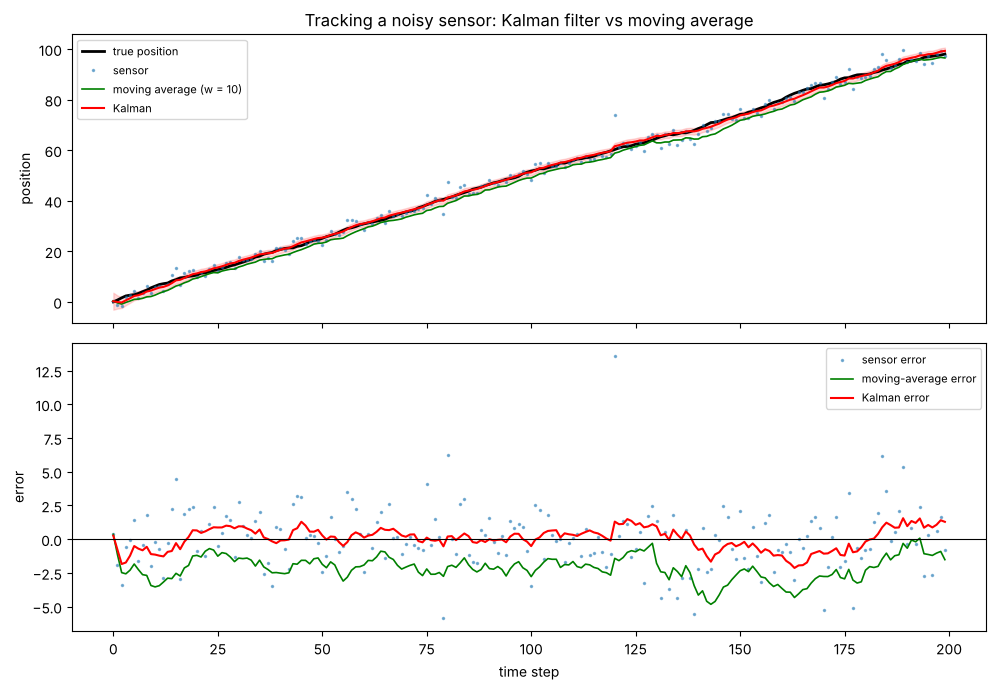


error right after the outlier at t = 120: sensor +13.59, Kalman +1.30, Kalman 5 steps later +1.06  (the gain K = 0.11 damps the glitch and the filter recovers)


In [21]:
rng = np.random.default_rng(2024)
T, dt = 200, 1.0
v_true, q, r = 0.5, 0.05, 4.0                      # true velocity, process noise variance, sensor noise variance

# --- synthetic track and measurements ---
x_true = np.empty(T); x_true[0] = 0.0
for t in range(1, T):
    x_true[t] = x_true[t - 1] + v_true * dt + rng.normal(0, np.sqrt(q))
z = x_true + rng.normal(0, np.sqrt(r), T)
z[120] += 15.0                                     # one gross outlier (sensor glitch)

def kalman_1d(z, v, q, r, mu0, P0):
    mus, Ps, Ks = np.empty(len(z)), np.empty(len(z)), np.empty(len(z))
    mu, P = mu0, P0
    for t, zt in enumerate(z):
        if t > 0:
            mu, P = mu + v * dt, P + q                 # predict
        K = P / (P + r)                                # gain
        mu, P = mu + K * (zt - mu), (1 - K) * P        # update
        mus[t], Ps[t], Ks[t] = mu, P, K
    return mus, Ps, Ks

def moving_average(z, window):
    out = np.empty_like(z)
    for t in range(len(z)):
        out[t] = z[max(0, t - window + 1): t + 1].mean()    # causal (uses only past and present)
    return out

rmse = lambda est: float(np.sqrt(np.mean((est - x_true)**2)))
mus, Ps, Ks = kalman_1d(z, v_true, q, r, mu0=0.0, P0=10.0)
print(f"RMSE  raw sensor      : {rmse(z):.3f}")
for wdw in (3, 5, 10, 20):
    print(f"RMSE  moving avg w={wdw:2d}: {rmse(moving_average(z, wdw)):.3f}")
print(f"RMSE  Kalman filter   : {rmse(mus):.3f}")

P_inf = (q + np.sqrt(q**2 + 4*q*r)) / 2
print(f"\nsteady state: P- = {P_inf:.3f}, K = {P_inf/(P_inf + r):.3f}, filtered sd = {np.sqrt(P_inf*r/(P_inf + r)):.3f}  vs sensor sd {np.sqrt(r):.3f}")
print(f"filter's final gain {Ks[-1]:.3f}, final sd {np.sqrt(Ps[-1]):.3f}")
inside = np.mean(np.abs(mus - x_true) <= 2 * np.sqrt(Ps))
print(f"fraction of time steps with the truth inside the +/-2 sd band: {inside:.3f}  (about 0.95 if the filter is calibrated)")

# --- misspecified velocity: the filter lags behind ---
mus_wrong, _, _ = kalman_1d(z, 0.0, q, r, 0.0, 10.0)
print(f"\nKalman with the wrong velocity model (v = 0): RMSE {rmse(mus_wrong):.3f}, mean error (bias) {np.mean(mus_wrong - x_true):+.3f}")
mus_bigq, _, _ = kalman_1d(z, 0.0, 2.0, r, 0.0, 10.0)
print(f"... same wrong model but q raised to 2.0:    RMSE {rmse(mus_bigq):.3f}, bias {np.mean(mus_bigq - x_true):+.3f}  (more trust in the sensor, less lag)")

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
axes[0].plot(x_true, "k", lw=2, label="true position")
axes[0].plot(z, ".", ms=3, alpha=0.5, label="sensor")
axes[0].plot(moving_average(z, 10), "g", lw=1.2, label="moving average (w = 10)")
axes[0].plot(mus, "r", lw=1.5, label="Kalman")
axes[0].fill_between(np.arange(T), mus - 2*np.sqrt(Ps), mus + 2*np.sqrt(Ps), color="r", alpha=0.15)
axes[0].set_ylabel("position"); axes[0].set_title("Tracking a noisy sensor: Kalman filter vs moving average"); axes[0].legend(fontsize=8)
axes[1].plot(z - x_true, ".", ms=3, alpha=0.5, label="sensor error")
axes[1].plot(moving_average(z, 10) - x_true, "g", lw=1.2, label="moving-average error")
axes[1].plot(mus - x_true, "r", lw=1.5, label="Kalman error")
axes[1].axhline(0, color="k", lw=0.8); axes[1].set_xlabel("time step"); axes[1].set_ylabel("error"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"\nerror right after the outlier at t = 120: sensor {z[120] - x_true[120]:+.2f}, Kalman {mus[120] - x_true[120]:+.2f}, "
      f"Kalman 5 steps later {mus[125] - x_true[125]:+.2f}  (the gain K = {Ks[120]:.2f} damps the glitch and the filter recovers)")

## Score

In [22]:
summary()


Score: 77/77 checks passed  🎉
